In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier , plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

## Q1. Business problem and target variable
**Business problem (simple):** The bank phones customers to sell a *term deposit* (a savings product). Each call costs time and money, and most people say no. We want to guess **who will say yes before we call**, so the bank can call the best people first.

**Target variable:** the column `y`
- `yes` = the customer subscribed (we use 1)
- `no` = the customer did not subscribe (we use 0)

#Understand Data

## Q2. Rows, columns, class counts and null values

In [ ]:
df=pd.read_csv("/content/bank-full.csv",sep=';')


In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df.shape

(45211, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
df.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['y'].value_counts()

,count
y,
no,39922
yes,5289


In [ ]:
(df['y'].value_counts(normalize=True)*100).round(2)

,proportion
y,
no,88.3
yes,11.7


**Answer:**
- Rows: **45,211**  |  Columns: **17** (16 inputs + the target `y`)
- Class counts: **no = 39,922 (88.3%)**, **yes = 5,289 (11.7%)**
- Null values: **none**. Duplicate rows: **0**.
- Some columns have the word `unknown`. It is not a null, so we keep it as a normal category.
- The classes are **not balanced** (many more "no"). So we will not trust accuracy alone.

#EDA

## Q3. Three EDA charts and what each one shows

**Chart 1 – Target balance (`y`)**

<Axes: xlabel='y'>

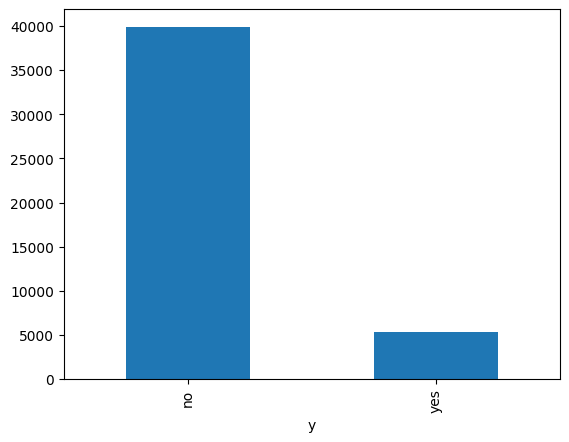

In [ ]:
df['y'].value_counts().plot(kind='bar')

**What it shows:** The "no" bar is much taller than the "yes" bar. Only about 1 in 9 customers subscribed (11.7%).
**Why it matters:** A model that always says "no" would already be about 88% correct, so accuracy can fool us. We must also check Precision, Recall and F1.

**Chart 2 – Age distribution**

<Axes: >

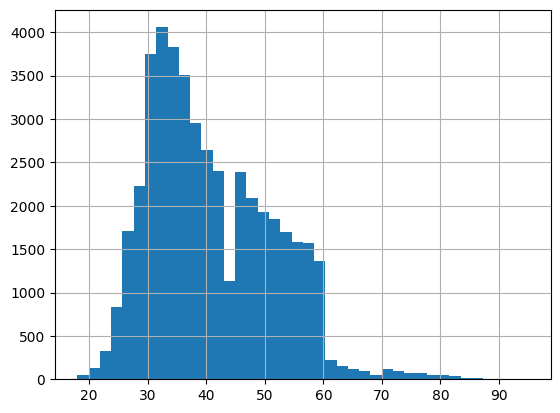

In [ ]:
df['age'].hist(bins=40)

**What it shows:** Customers are mostly adults between about 33 and 48 years old (the middle 50%). The youngest is 18, the oldest is 95, and the average is about 41. There are fewer older customers, so the chart leans to the right.
**Why it matters:** The bank mainly talks to working-age people, and very old ages are rare (few examples for the model to learn from).

**Chart 3 – Housing loan vs. subscription**

<Axes: xlabel='housing'>

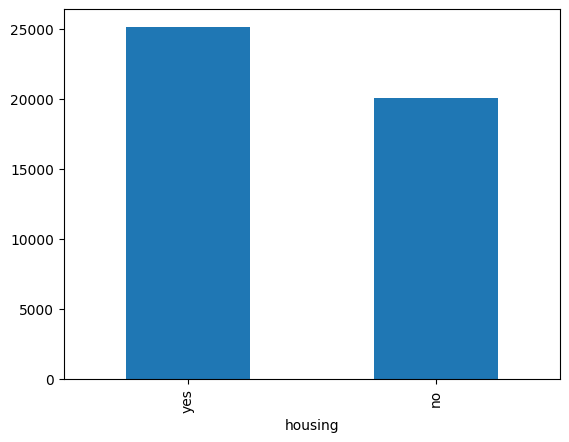

In [ ]:
df['housing'].value_counts().plot(kind='bar')

In [ ]:
pd.crosstab(df['housing'],df['y'])

y,no,yes
housing,,
no,16727,3354
yes,23195,1935


<Axes: xlabel='housing'>

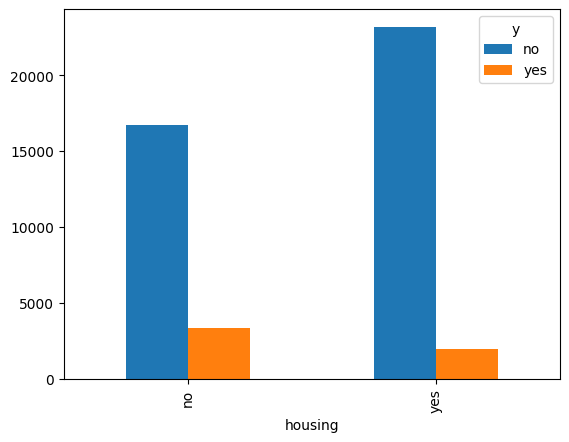

In [ ]:
pd.crosstab(df['housing'],df['y']).plot(kind='bar')

**What it shows:** Customers **without** a housing loan subscribed more (3,354 of 20,081, about **16.7%**) than customers **with** a housing loan (1,935 of 25,130, about **7.7%**).
**Why it matters:** Someone who is paying a house loan has less spare money, so `housing` helps predict who will say yes.

*(Extra chart, optional – education vs. subscription)*

<Axes: xlabel='education'>

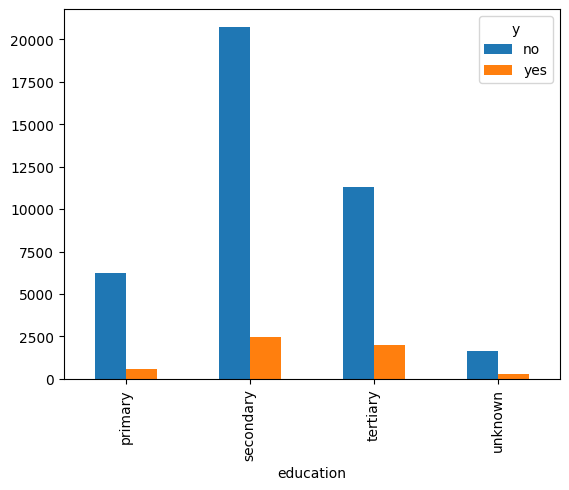

In [ ]:
pd.crosstab(df['education'],df['y']).plot(kind='bar')

## Q4. Why we exclude `duration`
`duration` is how long the phone call lasted (in seconds). We only know it **after** the call is finished, and a long call usually means the customer was interested.
So at the moment we need to decide **whom to call**, we do not have it yet. If we used it, the model would look very good in the notebook but would be useless in real life. This mistake is called **data leakage**. So we remove `duration` from the inputs (you will see it in the next cell).

#ML

## Q5. Why we use train / validation / test split
We split the data into 3 parts (60% / 20% / 20%):
- **Train** – the model learns from it.
- **Validation** – we use it to compare the 6 models and choose the best one.
- **Test** – we use it **once** at the end, to get an honest result on new customers.

If we chose the model using the test set, the test would not be "new" anymore and our final result would look better than it really is.

In [ ]:
X = df.drop(columns=['y','duration'])   # duration is removed (Q4)
y = df['y'].map({'no':0,'yes':1})

X_train_full,X_test,y_train_full,y_test = train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
X_train,X_valid,y_train,y_valid = train_test_split(X_train_full,y_train_full,random_state=42,stratify=y_train_full)

print('Train:',X_train.shape,' Validation:',X_valid.shape,' Test:',X_test.shape)

## Q6. Encoding and scaling (and why we fit on training data)
- **Encoding:** Models understand numbers only. So we change text columns (job, marital, housing...) into 0/1 columns using `get_dummies`.
- **Scaling:** Some columns are big (balance can be thousands) and some are small (age). `StandardScaler` puts them on a similar scale so the big ones don't dominate. This is needed for Logistic Regression, KNN, SVM and Naive Bayes. The tree models don't need it.
- **Why fit on train only:** The scaler learns the mean and spread from the data. If it learns from validation/test, the model "peeks" at data it should not have seen, and the results look too good. So: `fit` on train, then only `transform` validation and test.

In [ ]:
# Learn missing-value replacements from TRAIN only (there are no nulls here, but this is the safe way)
X_train, X_valid, X_test = X_train.copy(), X_valid.copy(), X_test.copy()
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()

for col in numeric_cols:
    median = X_train[col].median()
    for data in [X_train, X_valid, X_test]:
        data[col] = data[col].fillna(median)

for col in categorical_cols:
    most_common = X_train[col].mode()[0]
    for data in [X_train, X_valid, X_test]:
        data[col] = data[col].fillna(most_common)

# Encode categories (same get_dummies approach used in class)
X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
X_valid = pd.get_dummies(X_valid, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)

X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print('Number of input columns after encoding:', X_train.shape[1])

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit ONLY on train
X_valid_scaled = scaler.transform(X_valid)       # transform only
X_test_scaled = scaler.transform(X_test)         # transform only

## Q7. Train the six algorithms and compare on validation
The six models: Logistic Regression, KNN, Decision Tree, Random Forest, SVM, Naive Bayes.

How to read the table (simple):
- **Accuracy** – out of all customers, how many predictions are correct.
- **Precision** – when we say "yes", how often are we right.
- **Recall** – out of all real "yes" customers, how many we found.
- **F1** – one score that balances Precision and Recall.

Because "yes" is rare, we choose the model with the **best F1**.

In [ ]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), True),
    'KNN': (KNeighborsClassifier(n_neighbors=7), True),
    'Decision Tree': (DecisionTreeClassifier(max_depth=8, min_samples_leaf=7, random_state=42), False),
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_depth=7, min_samples_leaf=5, random_state=42), False),
    'SVM': (SVC(kernel='rbf', C=1, gamma='scale'), True),
    'Naive Bayes': (GaussianNB(), True)
}

trained_models = {}
results = []
for name, (model, needs_scaling) in models.items():
    train_data = X_train_scaled if needs_scaling else X_train
    valid_data = X_valid_scaled if needs_scaling else X_valid
    model.fit(train_data, y_train)
    pred = model.predict(valid_data)
    trained_models[name] = model
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_valid, pred),
        'Precision': precision_score(y_valid, pred, zero_division=0),
        'Recall': recall_score(y_valid, pred, zero_division=0),
        'F1': f1_score(y_valid, pred, zero_division=0)
    })
    print('Finished:', name)

results_df = pd.DataFrame(results).sort_values('F1', ascending=False)
display(results_df.round(3))

**Answer:** Look at the table above. The first row (highest F1) is our selected model. Notice that a model can have high Accuracy but low Recall (it misses many real "yes" customers) – that is why F1 is a better judge here.

## Q8. Confusion matrix of the selected model
A confusion matrix is a 2×2 table. Rows = the real answer, columns = what the model predicted:
- **True Positive** – we said yes, and the customer really said yes (good call).
- **False Positive** – we said yes, but the customer said no (wasted call).
- **False Negative** – we said no, but the customer would have said yes (missed customer).
- **True Negative** – we said no, and the customer said no (correct).

In [ ]:
best_name = results_df.iloc[0]['Model']
best_model = trained_models[best_name]
needs_scaling = models[best_name][1]

X_valid_final = X_valid_scaled if needs_scaling else X_valid
valid_pred = best_model.predict(X_valid_final)

ConfusionMatrixDisplay(confusion_matrix(y_valid, valid_pred), display_labels=['No', 'Yes']).plot()
plt.title(best_name + ' — validation confusion matrix')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_valid, valid_pred).ravel()
print('True Negative  :', tn)
print('False Positive :', fp, '(wasted calls)')
print('False Negative :', fn, '(missed customers)')
print('True Positive  :', tp, '(good calls)')

In [ ]:
# Final check on the TEST set (used only once)
X_final_test = X_test_scaled if needs_scaling else X_test
test_pred = best_model.predict(X_final_test)

print('Best validation model:', best_name)
print('Test accuracy:', round(accuracy_score(y_test, test_pred), 3))
print('Test F1:', round(f1_score(y_test, test_pred), 3))
print(classification_report(y_test, test_pred, target_names=['No', 'Yes']))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=['No', 'Yes']).plot()
plt.title(best_name + ' — test confusion matrix')
plt.show()

**Answer:** The model is good at spotting the "no" customers, but it misses a part of the real "yes" customers (see False Negatives). This is normal when "yes" is rare.

## Q9. Predict a new customer and change at least 3 fields
We make one customer (A), then make a copy (B) and change **4 fields**: `housing`, `poutcome`, `previous`, `pdays`. The new customer must go through the **same** encoding and the **same** scaler as the training data.

In [ ]:
def predict_customer(customer):
    row = pd.DataFrame([customer])
    row = pd.get_dummies(row, columns=categorical_cols, dtype=int)
    row = row.reindex(columns=X_train.columns, fill_value=0)
    row_in = scaler.transform(row) if needs_scaling else row
    label = best_model.predict(row_in)[0]
    prob = best_model.predict_proba(row_in)[0,1] if hasattr(best_model,'predict_proba') else None
    return label, prob

customer_A = {'age':40,'job':'management','marital':'married','education':'tertiary',
              'default':'no','balance':1500,'housing':'yes','loan':'no','contact':'cellular',
              'day':15,'month':'may','campaign':2,'pdays':-1,'previous':0,'poutcome':'unknown'}

# 4 changed fields: housing, poutcome, previous, pdays
customer_B = {**customer_A, 'housing':'no', 'poutcome':'success', 'previous':2, 'pdays':90}

for name, c in [('Customer A (original)', customer_A), ('Customer B (changed)', customer_B)]:
    label, prob = predict_customer(c)
    print(name, '-> prediction:', 'YES' if label==1 else 'NO',
          '| probability of yes:', None if prob is None else round(prob,3))

**Answer:** Compare the two lines above. Customer B has no housing loan and a successful earlier campaign. In the EDA these were linked to more "yes" answers, so B should look more likely to subscribe than A. This is only the model's estimate, not a promise. (If the selected model is SVM, only YES/NO is shown because it has no probability.)

## Q10. Three practical recommendations and limitations
**Recommendations**
1. **Call the best people first.** Use the model to sort customers, and call the ones with the highest chance of "yes" first. This saves calls.
2. **Focus on the right groups.** Customers whose earlier campaign was a success, and customers without a housing loan, are more likely to say yes.
3. **Keep checking and updating.** Watch Precision and Recall (not only Accuracy), and retrain the model with new data from time to time.

**Limitations**
- "Yes" is rare, so the model misses some real "yes" customers.
- The data is from one bank in one period, so it may not work for other banks or years.
- We did not tune the models (not required), so they could be better.
- We removed `duration` to avoid leakage, so the score is lower but honest.
- A link in the data does not prove a cause (for example, no housing loan does not *cause* a "yes").